Edited by: Darío Julián Echeverría Castro

# **Tutorial:** Custom YOLO Object Detection with RoboFlow

In this tutorial, you'll learn how to create a custom YOLO object detection model using your own classes and annotations with RoboFlow.

### **Step 1: Install Required Dependencies**

In [ ]:
#%pip install --upgrade ultralytics
#%pip install opencv-python
##%pip install roboflow
#%pip install matplotlib
#%pip install numpy==1.26.4 --force-reinstall

  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached filetype-1.2.0-py2.py3-none-any.whl.metadata (6.5 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ---------------------------------------- 0.0/7.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/7.4 MB ? eta -:--:--
   ---- ----------------------------------- 0.8/7.4 MB 2.6 MB/s eta 0:00:03
   --------- ------------------------------ 1.8/7.4 MB 3.9 MB/s eta 0:00:02
   --------------------- ------------------ 3.9/7.4 MB 6.0 MB/s eta 0:00:01
   ---------------------------------------- 7.4/7.4 MB 9.1 MB/s  0:00:00
   ---------------------------------------- 0.0/43.8 MB ? eta -:--:--
   ---- ----------------------------------- 5.0/43.8 MB 26.1 MB/s eta 0:00:02
   ---- ----------------------------------- 5.0/43.8 MB 26.1 MB/s eta 0:00:02
   --------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


Note: you may need to restart the kernel to use updated packages.


### **Step 2: Import Required Libraries**

In [1]:
import cv2
from roboflow import Roboflow
from ultralytics import YOLO
import matplotlib.pyplot as plt
import numpy as np
import os
from IPython.display import Image, display

### **Step 3: Set Up RoboFlow Account**

1. Go to RoboFlow and create a free account
2. Create a new project and select "Object Detection" as project type
3. Choose "YOLOv26" as the model format

### **Step 4: Upload and Annotate Your Images**

#### Using RoboFlow Web Interface:

1. Click "Upload" to add your images
2. Use the annotation tool to draw bounding boxes around objects
3. Assign the correct class labels to each bounding box
4. Apply preprocessing and augmentation as needed

### **Step 5. Download your Custom your Dataset**

1. In RoboFlow, go to your project dashboard
2. Click "Generate" to create a dataset version
3. Apply any desired augmentations
4. Click "Export" and select "YOLOv**x**" format (**x** the version you are using)
5. Copy the download code

In [ ]:
#!pip install roboflow
from roboflow import Roboflow
rf = Roboflow(api_key="*API_KEY*")
project = rf.workspace("julins-workspace-sqgtf").project("mcd_3fia_object_detection")
version = project.version(1)
dataset = version.download("yolo26")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to MCD_3FIA_object_detection-1 in yolo26:: 100%|██████████| 209/209 [00:00<00:00, 2901.67it/s]


### **Step 6: Train Your Custom YOLO Model**

In [3]:
OUTPUT_DIR = 'runs/detect/custom_yolo_model'

# Load the YOLO model with custom configuration
model = YOLO('yolo26n.pt')  # Using nano version as base

# Train the model on your custom dataset
results = model.train(
    data=f'{dataset.location}/data.yaml',  # Path to dataset config
    epochs=20,  # Number of training epochs
    imgsz=640,  # Image size
    batch=8,   # Batch size
    name='custom_yolo_model'  # Name for the training run
)

Ultralytics 8.4.210  Python-3.13.18 torch-2.15.0+cpu CPU (11th Gen Intel Core i7-11800H @ 2.30GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=d:\MCD_UITEY\3_fundamentos_de_inteligencia_artificial\clase13\actividad\MCD_3FIA_object_detection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937,

### **Step 7: Evaluate Your Model**

In [5]:
# Evaluate model performance
metrics = model.val()  # Validate the model
print(f"mAP50-95: {metrics.box.map}")
print(f"mAP50: {metrics.box.map50}")

# Show some validation results
%yolo task=detect mode=val model=runs/detect/custom_yolo_model/weights/best.pt data={dataset.location}/data.yaml

Ultralytics 8.4.210  Python-3.13.18 torch-2.15.0+cpu CPU (11th Gen Intel Core i7-11800H @ 2.30GHz)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 426.5±124.4 MB/s, size: 39.7 KB)
val: Scanning D:\MCD_UITEY\3_fundamentos_de_inteligencia_artificial\clase13\actividad\MCD_3FIA_object_detection-1\valid\labels.cache... 9 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 9/9 3.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.0it/s 0.5s
                   all          9         10      0.985          1      0.995      0.878
                 grogu          3          3      0.984          1      0.995      0.912
                totoro          7          7      0.986          1      0.995      0.844
Speed: 1.6ms preprocess, 46.9ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to D:\MCD_UITEY\3_fundamentos_de_inteli

UsageError: Line magic function `%yolo` not found.


In [6]:
# Validar el mejor modelo entrenado sobre el conjunto de validación
best_model = YOLO("runs/detect/custom_yolo_model/weights/best.pt")
val_metrics = best_model.val(data=f"{dataset.location}/data.yaml")
print(f"mAP50-95: {val_metrics.box.map:.3f}")
print(f"mAP50:    {val_metrics.box.map50:.3f}")

Ultralytics 8.4.210  Python-3.13.18 torch-2.15.0+cpu CPU (11th Gen Intel Core i7-11800H @ 2.30GHz)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 350.5±100.1 MB/s, size: 38.6 KB)
val: Scanning D:\MCD_UITEY\3_fundamentos_de_inteligencia_artificial\clase13\actividad\MCD_3FIA_object_detection-1\valid\labels.cache... 9 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 9/9 2.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.9it/s 0.5s
                   all          9         10      0.985          1      0.995      0.878
                 grogu          3          3      0.984          1      0.995      0.912
                totoro          7          7      0.986          1      0.995      0.844
Speed: 1.6ms preprocess, 46.6ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to D:\MCD_UITEY\3_fundamentos_de_inteli

### **Step 8: Test Your Custom Model on an Image**


image 1/1 d:\MCD_UITEY\3_fundamentos_de_inteligencia_artificial\clase13\actividad\test.jpeg: 384x640 1 grogu, 1 totoro, 61.8ms
Speed: 2.0ms preprocess, 61.8ms inference, 0.7ms postprocess per image at shape (1, 3, 384, 640)


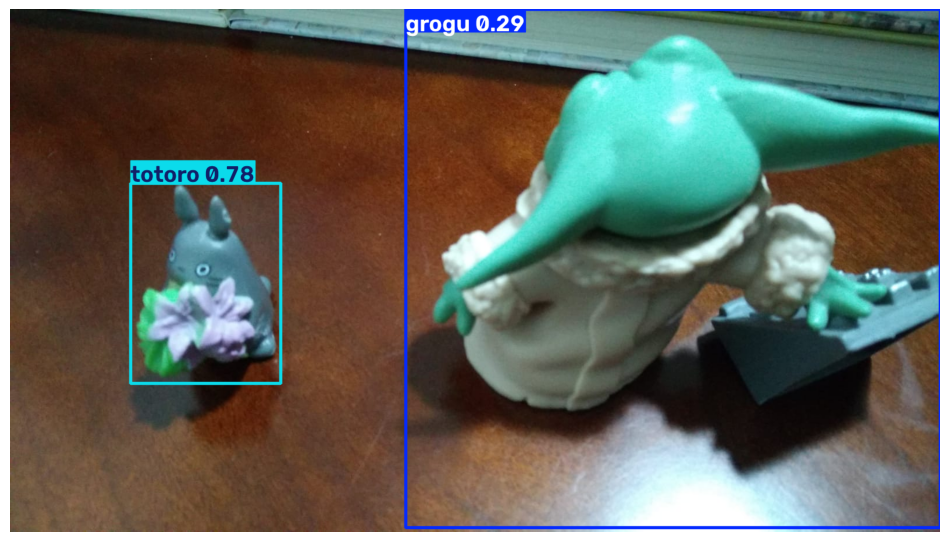

In [12]:
# Load your custom trained model
custom_model = YOLO('runs/detect/custom_yolo_model/weights/best.pt')

# Test on a sample image
#results = custom_model('totoro_test_2.jpg', conf=0.25)
results = custom_model('test.jpeg', conf=0.25)

# Display results
%matplotlib inline
for result in results:
    img = result.plot()  # Plot detections
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(12, 8))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.show()

### **Step 9: Test Your Custom Model on Video**

In [ ]:
# Detección en tiempo real con la webcam usando el modelo personalizado (grogu / totoro)

# Cargar el mejor modelo entrenado en las celdas anteriores
best_weights = os.path.join(OUTPUT_DIR, "weights", "best.pt")
custom_model = YOLO(best_weights)

# Nombres de las clases tomados directamente del modelo entrenado: {0: 'grogu', 1: 'totoro'}
classNames = custom_model.names

# Umbral mínimo de confianza para mostrar una detección
CONF_THRESHOLD = 0.45

# Un color distinto (BGR) por clase para diferenciar las detecciones
class_colors = {0: (0, 255, 0),    # grogu  -> verde
                1: (255, 0, 0)}    # totoro -> azul

# Configurar la captura de video desde la cámara por defecto
capture = cv2.VideoCapture(0)
capture.set(cv2.CAP_PROP_FRAME_WIDTH, 640)   # Ancho de la imagen
capture.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)  # Alto de la imagen

import math

if not capture.isOpened():
    print("Error: no se pudo abrir la cámara.")
else:
    print("Cámara iniciada. Presiona 'q' en la ventana de video para salir.")

    while True:
        success, img = capture.read()  # Capturar un frame
        if not success:
            print("No se pudo leer el frame de la cámara.")
            break

        # Detección con el modelo personalizado (stream=True devuelve un generador)
        results = custom_model(img, stream=True, conf=CONF_THRESHOLD, verbose=False)

        for r in results:
            for box in r.boxes:
                # Coordenadas de la caja en formato xyxy, convertidas a enteros
                x1, y1, x2, y2 = map(int, box.xyxy[0])

                # Confianza (0 a 1) redondeada a dos decimales
                confidence = math.ceil(float(box.conf[0]) * 100) / 100

                # Identificador numérico y nombre de la clase detectada
                cls = int(box.cls[0])
                label = f"{classNames[cls]} {confidence:.2f}"
                color = class_colors.get(cls, (255, 0, 255))

                # Dibujar la caja y la etiqueta sobre la imagen
                cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
                cv2.putText(img, label, (x1, max(y1 - 10, 20)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)

        # Mostrar la imagen procesada en una ventana
        cv2.imshow("Detección personalizada: grogu / totoro", img)

        # Salir del bucle al presionar 'q'
        if cv2.waitKey(10) & 0xFF == ord("q"):
            break

# Liberar la cámara y cerrar las ventanas
capture.release()
cv2.destroyAllWindows()

## **Activity: Create Your Custom Detector**

1. **Create a RoboFlow account** and set up a new project
2. **Upload at least 25 images** of your custom objects (at least 2)
3. **Annotate all images** with bounding boxes and class labels
4. **Train a YOLO model** on your custom dataset
5. **Test your model** on new images and evaluate its performance
6. **Implement real-time detection** with your custom classes

## **Grading Rubric:**

| **Criteria** | **Points** | **Description** |
|-------------|-----------|----------------|
| **1. Dataset Creation** | 4 | Successfully creates and annotates a custom dataset with at least 25 images and multiple classes in RoboFlow. |
| **2. Model Training** | 1 | Properly trains a YOLOv26 model on the custom dataset with appropriate hyperparameters. |
| **3. Model Evaluation** | 1 | Evaluates model performance with appropriate metrics and provides analysis of results. |
| **4. Custom Detection** | 3 | Implements real-time detection with custom classes and displays results correctly. You have to use video from your webcam, no images or saved videos allowed. |
| **5. Documentation** | 1 | Provides clear documentation of the process, including dataset details and model performance. |

**Total: 10 points**

## **Tips for Success:**

- **Quality over quantity**: Well-annotated images are more important than many poorly annotated ones
- **Class balance**: Try to have a similar number of examples for each class
- **Variety**: Include different angles, lighting conditions, and backgrounds
- **Augmentation**: Use RoboFlow's augmentation features to expand your dataset

<p style="text-align: right; font-size:14px; color:gray;">
<b>Prepared by:</b><br>
Manuel Eugenio Morocho-Cayamcela
</p>